# Retrain phishing detection with frozen domain splits (v5: strict release)
Run locally in the API directory with a **Python 3.12** notebook kernel. Run the installation cell, restart the kernel if packages changed, then Run All. No submitted target URLs are visited.

This notebook fixes the v2 comparison: it **never loads the deployed model to calculate comparison metrics**. All three representations are fitted from scratch on exactly the same training rows and correction weights. Vocabulary and scalers learn only from training data; model/threshold selection uses validation only. The test set evaluates the frozen choices, not hyperparameter selection. Warning and blocking thresholds are separate; infeasible automatic blocking is disabled instead of using an unsafe fallback.

A permanent `training_data/frozen_splits_v3.json` locks dataset labels, grouping, and train/validation/test domain assignments. Commit this file. A rerun, seed change, row shuffle, or training-only sample limit cannot silently redefine the test set. Dataset/correction changes require a new named experiment; results from different experiment files are not directly comparable.

These remain **historical development data**, not a newly collected real-world or chronological holdout. Repeatedly inspecting the same test data makes it development evidence. Recent independently verified benign/phishing URLs are still needed for final deployment assurance.

The Instagram/Facebook/Google corrections are training feedback, not independent test accuracy. Their entire domain groups remain training-only. There is no trusted-domain bypass.

Run All is sufficient: an empty reviewed-training template is valid. Every run creates a validation review queue, training coverage, and review-decision report. To add verified training examples, fill `training_data/reviewed_training_urls.csv` with URL, 0/1 label, evidence, reviewer, and date. Held-out domains are rejected from training. A queue entry is not proof that its dataset label is wrong; blank labels are intentional. Never import prediction outputs as truth.

**Final profile: STRICT**, as requested. Validation and test must meet precision >=90%, recall >=80%, and benign warning rate <=3%. Export rechecks locked limits independently of notebook settings. A passing run creates a standalone `github_api_release/` folder with hashes, model report, exact helper, compatible dependencies, and verification script. Failed runs preserve the runtime model and create no release folder. No weaker assistive profile is enabled.


In [29]:
# Match the Render runtime's model-library versions; use Python 3.12.
%pip install -r requirements.txt "matplotlib==3.11.2" "tldextract==5.4.0"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [30]:
from pathlib import Path
from datetime import datetime, timezone
import gc
import hashlib
import importlib.metadata
import json
import shutil
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import tldextract
from IPython.display import display
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay

ROOT = Path.cwd().resolve()
if ROOT.name == 'training_data': ROOT = ROOT.parent
if not (ROOT / 'training_data').is_dir():
    raise FileNotFoundError('Run this notebook from extension-setup/api or its training_data folder.')
# Load the exact local source, bypassing stale modules AND bytecode caches.
import runpy
_helper_namespace = runpy.run_path(str(ROOT / 'refresh_training_helpers.py'))
globals().update(_helper_namespace['HELPER_EXPORTS'])

SEED = 42
DATA_DIR = ROOT / 'training_data'
SPLIT_PATH = DATA_DIR / 'frozen_splits_v3.json'  # Reused on every run. Do not delete to chase a better score.
MAX_TRAIN_ROWS_PER_SOURCE = None  # Optional training-only limit; validation/test stay fixed.
MAX_TFIDF_FEATURES = 200_000
MIN_DOCUMENT_FREQUENCY = 3
INCLUDE_DATA2 = False  # bad/good may not mean phishing/benign; confirm before enabling.
INCLUDE_DATA3 = False  # Confirm its original 1/0 label convention before enabling.
CORRECTION_SAMPLE_WEIGHT = 50.0
THRESHOLD_BETA = 2.0
DEPLOYMENT_PROFILE = 'strict'  # Explicit user choice; never weaken acceptance limits.
QUALITY_POLICY = dict(STRICT_QUALITY_POLICY)
# Local promotion is automatic ONLY if all validation/test/regression/reload gates pass.
# This NEVER pushes Git or deploys Render. False always preserves the runtime model.
PROMOTE_MODEL = True
RUN_DIR = ROOT / 'artifacts' / ('url_retraining_v5_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
RUNTIME_MODEL_PATH = ROOT / 'dataset' / 'phishing_url_bundle.joblib'
# A verified new experiment gets its OWN data and split manifest.
SOURCE_PATHS, _experiment_split, ACTIVE_DATASET_EXPERIMENT = resolve_active_experiment(ROOT)
if _experiment_split is not None:
    SPLIT_PATH = _experiment_split
    print('Active source-restored experiment:', ACTIVE_DATASET_EXPERIMENT['experiment'])
else:
    print('Original historical dataset: no verified source-restoration experiment is active.')
print('Frozen split file:', SPLIT_PATH)
print('Run output:', RUN_DIR)
print('Promotion policy:', QUALITY_POLICY)
BLOCK_POLICY = dict(STRICT_BLOCK_POLICY)
REVIEWED_TRAINING_PATH = DATA_DIR / 'reviewed_training_urls.csv'
REVIEW_SAMPLE_WEIGHT = 20.0
AUDIT_QUEUE_LIMIT = 500
print('Automatic-block policy:', BLOCK_POLICY)
TRAINING_HELPER_SHA256 = sha256_file(ROOT / 'phishing_url_utils.py')

SOURCE_PROVENANCE_READY = bool(ACTIVE_DATASET_EXPERIMENT and ACTIVE_DATASET_EXPERIMENT.get('source_reference_verified'))
if not SOURCE_PROVENANCE_READY:
    PROMOTE_MODEL = False
    print('PROVENANCE HOLD: the original corpus has unresolved source-label disagreements. Diagnostics may run, but promotion is disabled until a verified source-restored experiment is active. Read training_data/PROVENANCE_FINDINGS.md.')


Loaded training helpers directly from: C:\Users\perso\EJIE\Herd\phish-block-monitoring-system\extension-setup\api
normalized_model_urls available: True
Active source-restored experiment: phishstorm_restored_v1
Frozen split file: C:\Users\perso\EJIE\Herd\phish-block-monitoring-system\extension-setup\api\training_data\experiments\phishstorm_restored_v1\frozen_splits.json
Run output: C:\Users\perso\EJIE\Herd\phish-block-monitoring-system\extension-setup\api\artifacts\url_retraining_v5_20261025T023045464582Z
Promotion policy: {'min_precision': 0.9, 'min_recall': 0.8, 'max_false_positive_rate': 0.03, 'min_test_examples_per_class': 100}
Automatic-block policy: {'min_precision': 0.98, 'max_false_positive_rate': 0.005, 'min_predictions': 50}


## Load and audit the complete corpus before splitting
Only explicitly labeled phishing/benign data4 rows and verified PhishTank rows are included by default. Other data4 threat categories are not mislabeled as benign. Incompatible feature-only CSVs stay excluded. Resolve contradictory labels across the model representations before splitting; reviewed exact-URL corrections override only those exact model keys.


In [31]:
source_audit, frames = [], []
def add_source(filename, url_col, label_col=None, label_map=None, verified_only=False):
    df = pd.read_csv(SOURCE_PATHS.get(filename, DATA_DIR / filename), encoding='utf-8-sig', low_memory=False)
    raw_rows = len(df)
    if verified_only:
        df = df[df['verified'].astype(str).str.strip().str.lower().eq('yes')].copy()
        labels = pd.Series(1, index=df.index)
    else:
        labels = df[label_col].astype(str).str.strip().str.lower().map(label_map)
    eligible = labels.notna()
    part = pd.DataFrame({'url': df.loc[eligible, url_col],
        'label': labels.loc[eligible].astype('int8'), 'source': filename})
    part['url'] = part['url'].map(normalize_url)
    invalid = int(part['url'].isna().sum())
    frames.append(part.dropna(subset=['url']))
    source_audit.append({'source': filename, 'raw_rows': raw_rows,
        'eligible_rows': int(eligible.sum()), 'invalid_urls': invalid})

add_source('data4.csv', 'url', 'type', {'phishing': 1, 'benign': 0})
add_source('phishtank.csv', 'url', verified_only=True)
if INCLUDE_DATA2: add_source('data2.csv', 'URL', 'Label', {'bad': 1, 'good': 0})
if INCLUDE_DATA3: add_source('data3.csv', 'domain', 'label', {'1': 1, '0': 0})
raw = pd.concat(frames, ignore_index=True)
# Model keys let both www and non-www forms share conflict handling.
raw['model_key'] = model_text_urls(raw['url'])
label_counts = raw.groupby('model_key')['label'].nunique()
conflict_keys = set(label_counts[label_counts > 1].index)
conflicting_rows = raw[raw['model_key'].isin(conflict_keys)].copy()
clean = raw[~raw['model_key'].isin(conflict_keys)].drop_duplicates('url').copy()
reviewed = pd.read_csv(DATA_DIR / 'reviewed_urls.csv')
reviewed['url'] = reviewed['url'].map(normalize_url)
assert reviewed['url'].notna().all(), 'Invalid reviewed URL.'
assert set(reviewed['label']).issubset({0, 1}), 'Reviewed labels must be 0 or 1.'
reviewed['model_key'] = model_text_urls(reviewed['url'])
assert reviewed.groupby('model_key')['label'].nunique().max() == 1, 'Contradictory reviewed corrections.'
reviewed = reviewed.drop_duplicates('url').copy()
clean = clean[~clean['model_key'].isin(reviewed['model_key'])].copy()
clean['sample_weight'] = 1.0
reviewed['source'] = 'reviewed_urls.csv'
reviewed['sample_weight'] = CORRECTION_SAMPLE_WEIGHT
clean = pd.concat([clean[['url','label','source','sample_weight']],
                   reviewed[['url','label','source','sample_weight']]], ignore_index=True)
assert clean['url'].is_unique and set(clean['label']) == {0, 1}
print('Removed contradictory model keys:', len(conflict_keys))
print('Complete cleaned corpus:', len(clean))
display(pd.DataFrame(source_audit))
display(pd.crosstab(clean['source'], clean['label']).rename(columns={0:'benign',1:'phishing'}))

Removed contradictory model keys: 0
Complete cleaned corpus: 564023


,source,raw_rows,eligible_rows,invalid_urls
0,data4.csv,651192,522215,4040
1,phishtank.csv,51720,51720,8


label,benign,phishing
source,,
data4.csv,427516,85343
phishtank.csv,0,51158
reviewed_urls.csv,6,0


## Freeze and reuse domain assignments
The same registrable domain (including private suffix rules) never crosses partitions. SHA256 assigns each ordinary domain approximately 60/20/20, with reviewed domains fixed to training. Large domains can make row fractions uneven. Training-only sampling happens **after** this assignment; it cannot alter validation/test rows.

If the split file already exists, the notebook checks the complete dataset fingerprint and reuses it. Do not delete/edit the file to obtain easier results. New source data, labels, or grouping rules need a separately named experiment and newly collected final evaluation data.


In [32]:
from urllib.parse import urlsplit
extract_domain = tldextract.TLDExtract(suffix_list_urls=(), include_psl_private_domains=True)
def domain_group(url):
    host = urlsplit('http://' + url).hostname
    return extract_domain(host).top_domain_under_public_suffix or host

clean['group'] = clean['url'].map(domain_group)
reviewed_groups = set(reviewed['url'].map(domain_group))
assigned, frozen_manifest = freeze_splits(clean, SPLIT_PATH, reviewed_groups, seed=SEED)
train = assigned[assigned['split'].eq('train')].copy()
validation = assigned[assigned['split'].eq('validation')].reset_index(drop=True)
test = assigned[assigned['split'].eq('test')].reset_index(drop=True)
if MAX_TRAIN_ROWS_PER_SOURCE is not None:
    if not isinstance(MAX_TRAIN_ROWS_PER_SOURCE, int) or MAX_TRAIN_ROWS_PER_SOURCE < 2:
        raise ValueError('Training sample limit must be None or an integer >= 2.')
    sampled = []
    for source, part in train.groupby('source', sort=True):
        if source != 'reviewed_urls.csv' and len(part) > MAX_TRAIN_ROWS_PER_SOURCE:
            part = pd.concat([g.sample(n=max(1, int(len(g) * MAX_TRAIN_ROWS_PER_SOURCE / len(part))), random_state=SEED)
                              for _, g in part.groupby('label')])
        sampled.append(part)
    train = pd.concat(sampled, ignore_index=True)
# Reviewed additions may change TRAINING only. Frozen evaluation labels/rows stay intact.
train, review_decisions = apply_training_reviews(train, REVIEWED_TRAINING_PATH,
    set(validation['group']) | set(test['group']), domain_group, weight=REVIEW_SAMPLE_WEIGHT)
train = train.sort_values('url').reset_index(drop=True)
assert train['url'].is_unique
print('Applied reviewed training additions:', int(review_decisions['applied'].sum()) if len(review_decisions) else 0)
if len(review_decisions): display(review_decisions[['url','applied','reason']])
parts = {'train': train, 'validation': validation, 'test': test}
for name, part in parts.items():
    assert set(part['label']) == {0, 1}, f'{name} requires both classes.'
for a,b in [('train','validation'), ('train','test'), ('validation','test')]:
    assert set(parts[a]['group']).isdisjoint(parts[b]['group'])
    assert set(parts[a]['url']).isdisjoint(parts[b]['url'])
assert not reviewed_groups.intersection(set(validation['group']) | set(test['group']))
# Re-read verifies that this run did not rebuild or perturb the persisted assignments.
again, _ = freeze_splits(clean.sample(frac=1, random_state=99), SPLIT_PATH, reviewed_groups, seed=SEED)
assert dict(zip(again['url'], again['split'])) == dict(zip(assigned['url'], assigned['split']))
display(pd.DataFrame([{'split': name, 'rows': len(part), 'domains': part['group'].nunique(),
    'phishing_fraction': part['label'].mean()} for name,part in parts.items()]))
print('Dataset fingerprint:', frozen_manifest['dataset_fingerprint'])
# Training-data coverage is an audit, not evidence that a particular domain is safe.
coverage = train[['source','label']].copy()
coverage['homepage'] = train['url'].map(lambda u: urlsplit('http://' + u).path in {'','/'})
coverage['www_prefix'] = train['url'].str.startswith('www.')
coverage_report = coverage.groupby(['source','label']).agg(rows=('label','size'),
    homepages=('homepage','sum'), www_urls=('www_prefix','sum')).reset_index()
display(coverage_report)

Applied reviewed training additions: 30


,url,applied,reason
0,pandas.pydata.org/docs/user_guide/index.html,True,evidence-backed training feedback
1,pandas.pydata.org/docs/user_guide/10min.html,True,evidence-backed training feedback
2,pandas.pydata.org/docs/user_guide/io.html,True,evidence-backed training feedback
3,pandas.pydata.org/docs/user_guide/indexing.html,True,evidence-backed training feedback
4,pandas.pydata.org/docs/user_guide/text.html,True,evidence-backed training feedback
5,pandas.pydata.org/docs/user_guide/missing_data...,True,evidence-backed training feedback
6,scikit-learn.org/stable/user_guide.html,True,evidence-backed training feedback
7,scikit-learn.org/stable/supervised_learning.html,True,evidence-backed training feedback
8,scikit-learn.org/stable/modules/cross_decompos...,True,evidence-backed training feedback
9,laravel.com/docs/13.x/routing,True,evidence-backed training feedback


,split,rows,domains,phishing_fraction
0,train,348481,102279,0.250923
1,validation,118739,34445,0.200852
2,test,96833,34186,0.260345


Dataset fingerprint: f2555c8def477fa4b55f7b59d70abecf14eac89cfab10eca60208dcbec6d3e94


,source,label,rows,homepages,www_urls
0,data4.csv,0,261003,29731,18735
1,data4.csv,1,51673,16818,10909
2,phishtank.csv,1,35769,12607,1206
3,reviewed_training_urls.csv,0,30,6,10
4,reviewed_urls.csv,0,6,6,3


## Fit all approaches on the identical training rows
Each representation compares regularization/class weighting on validation only. Hostname and path/query vocabularies are separated in component models; an independently fitted nonlinear structure model can contribute a validation-selected soft vote. Raw URL and structure-only baselines are diagnostics, not production candidates. The raw-URL refit is the fair baseline; the previously deployed bundle is **not** evaluated or reused. A URL-structure branch adds offline numeric features without fetching a site. All learned preprocessing is fitted on training only.

Thresholds maximize validation F2 subject to the precision, recall, and false-positive policy. If no threshold meets every constraint, that fact is reported; a false-positive-constrained diagnostic threshold is saved but **promotion stays blocked**. A separate automatic-block threshold requires validation precision >=98%, FPR <=0.5%, and at least 50 predictions. If none exists, ML blocking is disabled before test evaluation. If selected, that threshold must pass the same block gates on test or the whole promotion is blocked. Quality limits are declared before viewing test results and should reflect your actual tolerance, not be lowered just to obtain a passing run.


In [33]:
representations = {
    'raw_url_refit': (normalized_model_urls, 'whole'),  # diagnostic baseline only
    'www_invariant_refit': (model_text_urls, 'whole'),
    'component_text': (model_text_urls, 'components'),
}
settings_grid = [('C1', {'C':1.0,'class_weight':None}),
                 ('C4', {'C':4.0,'class_weight':None}),
                 ('C4_balanced', {'C':4.0,'class_weight':'balanced'})]
models, validation_rows, decision_policies = {}, [], {}
regression_urls=['https://www.instagram.com/','https://instagram.com/',
    'https://www.facebook.com/','https://facebook.com/','https://www.google.com/','https://google.com/']

def record_candidate(name, family, model, scores, production_eligible=True):
    warning, feasible = select_threshold(validation['label'], scores, QUALITY_POLICY, beta=THRESHOLD_BETA)
    block = select_block_threshold(validation['label'], scores, warning, BLOCK_POLICY)
    decision_policies[name] = {'validated': True, 'block_threshold': block}
    metrics = metric_summary(validation['label'], scores, warning, beta=THRESHOLD_BETA)
    homepage_scores = model.predict_proba(regression_urls)[:,1]
    homepage_passed = bool((homepage_scores < warning).all())
    models[name]=model
    validation_rows.append({'model':name,'family':family,'threshold':warning,'block_threshold':block,
        'constraints_met':feasible,'homepage_checks_passed':homepage_passed,
        'production_eligible':production_eligible,
        'acceptable_validation':feasible and homepage_passed and production_eligible, **metrics})
    print(name,'recall:',round(metrics['recall'],3),'warning FPR:',round(metrics['false_positive_rate'],3),
          'warning policy:',feasible,'ML blocking:',block if block is not None else 'disabled')

for family,(normalizer,mode) in representations.items():
    started=time.perf_counter()
    if mode=='whole':
        features=TfidfVectorizer(analyzer='char',ngram_range=(3,5),lowercase=False,
            min_df=MIN_DOCUMENT_FREQUENCY,max_features=MAX_TFIDF_FEATURES,sublinear_tf=True,dtype=np.float32)
    else:
        features=FeatureUnion([
            ('host',Pipeline([('extract',FunctionTransformer(host_text_urls,validate=False)),
                ('tfidf',TfidfVectorizer(analyzer='char',ngram_range=(2,5),min_df=MIN_DOCUMENT_FREQUENCY,
                    max_features=max(100,int(MAX_TFIDF_FEATURES*.3)),sublinear_tf=True,dtype=np.float32))])),
            ('path_char',Pipeline([('extract',FunctionTransformer(path_query_text_urls,validate=False)),
                ('tfidf',TfidfVectorizer(analyzer='char',ngram_range=(3,5),lowercase=False,min_df=MIN_DOCUMENT_FREQUENCY,
                    max_features=max(100,int(MAX_TFIDF_FEATURES*.5)),sublinear_tf=True,dtype=np.float32))])),
            ('path_word',Pipeline([('extract',FunctionTransformer(path_query_text_urls,validate=False)),
                ('tfidf',TfidfVectorizer(ngram_range=(1,2),min_df=MIN_DOCUMENT_FREQUENCY,
                    max_features=max(100,int(MAX_TFIDF_FEATURES*.2)),sublinear_tf=True,dtype=np.float32))])),
            ('structure',Pipeline([('extract',FunctionTransformer(url_lexical_features,validate=False)),
                                   ('scale',StandardScaler(with_mean=False))])),
        ])
    preprocessing=Pipeline([('url_text',FunctionTransformer(normalizer,validate=False)),('features',features)])
    X_train=preprocessing.fit_transform(train['url'],train['label'])
    X_validation=preprocessing.transform(validation['url'])
    for suffix,settings in settings_grid:
        name=family+'_'+suffix
        classifier=LogisticRegression(solver='liblinear',max_iter=2000,random_state=SEED,**settings)
        classifier.fit(X_train,train['label'],sample_weight=train['sample_weight'].to_numpy())
        if int(classifier.n_iter_.max())>=classifier.max_iter:raise RuntimeError(name+' did not converge.')
        model=Pipeline([('preprocessing',preprocessing),('classifier',classifier)])
        record_candidate(name,family,model,classifier.predict_proba(X_validation)[:,1],family!='raw_url_refit')
    del X_train,X_validation
    gc.collect()
    print(family,'seconds:',round(time.perf_counter()-started,1))

# A nonlinear structure model is fitted independently, never on leaked in-sample text scores.
structure=Pipeline([('normalize',FunctionTransformer(model_text_urls,validate=False)),
    ('features',FunctionTransformer(dense_url_features,validate=False)),
    ('classifier',HistGradientBoostingClassifier(max_iter=200,max_leaf_nodes=31,
        learning_rate=.08,l2_regularization=2.0,random_state=SEED))])
structure.fit(train['url'],train['label'],classifier__sample_weight=train['sample_weight'].to_numpy())
record_candidate('structure_boost','structure_boost',structure,structure.predict_proba(validation['url'])[:,1],False)
component_rows=pd.DataFrame(validation_rows).query("family == 'component_text'").sort_values(
    ['acceptable_validation','constraints_met','fbeta'],ascending=False)
component_model=models[str(component_rows.iloc[0]['model'])]
for text_weight in [.8,.6]:
    model=UrlProbabilityEnsemble([component_model,structure],[text_weight,1-text_weight])
    record_candidate('component_vote_'+str(int(text_weight*100)),'component_vote',model,
                     model.predict_proba(validation['url'])[:,1])

validation_results=pd.DataFrame(validation_rows).sort_values(
    ['acceptable_validation','constraints_met','homepage_checks_passed','fbeta','average_precision'],
    ascending=False).reset_index(drop=True)
display(validation_results)
# Raw baseline and structure-only diagnostics cannot become production winners.
winner=validation_results[validation_results['production_eligible']].iloc[0]
selected_name,selected_threshold=str(winner['model']),float(winner['threshold'])
selected_pipeline=models[selected_name]
selected_family=str(winner['family'])
selected_block_threshold=decision_policies[selected_name]['block_threshold']
family_choices=validation_results.drop_duplicates('family').copy()
print('Frozen choice:',selected_name,'warning:',selected_threshold,'block:',selected_block_threshold)
if not bool(winner['acceptable_validation']):print('No deployment-ready candidate on validation; diagnostics will be exported.')

raw_url_refit_C1 recall: 0.834 warning FPR: 0.023 warning policy: True ML blocking: 0.8789956839081285
raw_url_refit_C4 recall: 0.867 warning FPR: 0.024 warning policy: True ML blocking: 0.9406590483072662
raw_url_refit_C4_balanced recall: 0.859 warning FPR: 0.024 warning policy: True ML blocking: 0.97177073495832
raw_url_refit seconds: 143.3
www_invariant_refit_C1 recall: 0.835 warning FPR: 0.023 warning policy: True ML blocking: 0.8757756316151666
www_invariant_refit_C4 recall: 0.864 warning FPR: 0.024 warning policy: True ML blocking: 0.937288433842925
www_invariant_refit_C4_balanced recall: 0.856 warning FPR: 0.024 warning policy: True ML blocking: 0.9712831343827623
www_invariant_refit seconds: 139.3
component_text_C1 recall: 0.791 warning FPR: 0.022 warning policy: False ML blocking: 0.930912879265462
component_text_C4 recall: 0.818 warning FPR: 0.023 warning policy: True ML blocking: 0.9855771120025342
component_text_C4_balanced recall: 0.822 warning FPR: 0.023 warning policy: T

,model,family,threshold,block_threshold,constraints_met,homepage_checks_passed,production_eligible,acceptable_validation,accuracy,balanced_accuracy,...,recall,f1,fbeta,roc_auc,average_precision,false_positive_rate,tn,fp,fn,tp
0,www_invariant_refit_C4,www_invariant_refit,0.445719,0.937288,True,True,True,True,0.953377,0.919833,...,0.863768,0.881547,0.870793,0.985634,0.952136,0.024102,92603,2287,3249,20600
1,www_invariant_refit_C4_balanced,www_invariant_refit,0.647566,0.971283,True,True,True,True,0.952080,0.916275,...,0.856430,0.877740,0.864828,0.985853,0.952352,0.023880,92624,2266,3424,20425
2,www_invariant_refit_C1,www_invariant_refit,0.429881,0.875776,True,True,True,True,0.948206,0.905783,...,0.834878,0.866223,0.847140,0.982997,0.945679,0.023311,92678,2212,3938,19911
3,component_text_C4_balanced,component_text,0.705060,0.992876,True,True,True,True,0.945957,0.899652,...,0.822257,0.859390,0.836718,0.983887,0.944370,0.022953,92712,2178,4239,19610
4,component_text_C4,component_text,0.552401,0.985577,True,True,True,True,0.945123,0.897357,...,0.817519,0.856823,0.832799,0.984123,0.945019,0.022805,92726,2164,4352,19497
5,raw_url_refit_C4,raw_url_refit,0.450165,0.940659,True,True,False,False,0.953890,0.921206,...,0.866577,0.883035,0.873086,0.985438,0.951509,0.024165,92597,2293,3182,20667
6,raw_url_refit_C4_balanced,raw_url_refit,0.652810,0.971771,True,True,False,False,0.952450,0.917307,...,0.858568,0.878836,0.866562,0.985687,0.951796,0.023954,92617,2273,3373,20476
7,raw_url_refit_C1,raw_url_refit,0.434827,0.878996,True,True,False,False,0.948046,0.905354,...,0.833997,0.865742,0.846412,0.982883,0.945270,0.023290,92680,2210,3959,19890
8,component_text_C1,component_text,0.550703,0.930913,False,True,True,False,0.940407,0.884549,...,0.791186,0.842103,0.810796,0.983551,0.943985,0.022089,92794,2096,4980,18869
9,component_vote_80,component_vote,0.678661,0.807609,False,True,True,False,0.940062,0.883564,...,0.789132,0.840986,0.809087,0.983475,0.945485,0.022004,92802,2088,5029,18820


Frozen choice: www_invariant_refit_C4 warning: 0.44571896267635086 block: 0.937288433842925


## Evaluate the frozen choices once
These models have never fitted on this test partition. All family winners were chosen before test predictions. Test results cannot change the chosen model or threshold. Do not compare these numbers against v1/v2 test tables from different splits. Homepage checks below are a separate training-feedback regression suite.


,model,family,threshold,accuracy,balanced_accuracy,precision,recall,f1,fbeta,roc_auc,average_precision,false_positive_rate,tn,fp,fn,tp
0,www_invariant_refit_C4,www_invariant_refit,0.445719,0.948633,0.924804,0.923595,0.875089,0.898688,0.884379,0.984578,0.965572,0.025481,69798,1825,3149,22061
1,component_text_C4_balanced,component_text,0.705060,0.953363,0.927899,0.941953,0.874772,0.907120,0.887430,0.988764,0.974719,0.018974,70264,1359,3157,22053
2,raw_url_refit_C4,raw_url_refit,0.450165,0.948953,0.924879,0.925188,0.874653,0.899211,0.884313,0.984442,0.965245,0.024894,69840,1783,3160,22050
3,component_vote_80,component_vote,0.678661,0.953724,0.923838,0.956445,0.861484,0.906484,0.878937,0.989008,0.975179,0.013808,70634,989,3492,21718
4,structure_boost,structure_boost,0.805131,0.858623,0.735922,0.954330,0.479929,0.638672,0.532911,0.910412,0.832811,0.008084,71044,579,13111,12099


              precision    recall  f1-score   support

      benign       0.96      0.97      0.97     71623
    phishing       0.92      0.88      0.90     25210

    accuracy                           0.95     96833
   macro avg       0.94      0.92      0.93     96833
weighted avg       0.95      0.95      0.95     96833



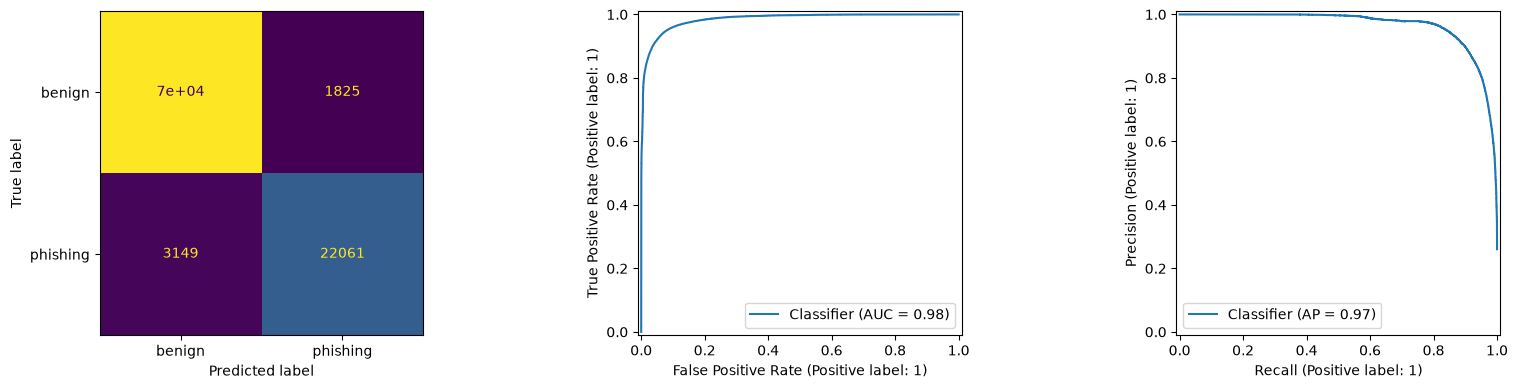

,source,rows,phishing_recall,false_positive_rate
0,data4.csv,88235,0.866241,0.025481
1,phishtank.csv,8598,0.892184,NaN


                                                                   url  label    source  phishing_score
                                                               ceu.hu/      0 data4.csv        0.847630
                                           cqgcr.ca/ang/producer01.php      0 data4.csv        0.561732
                               securityfirstinternationalholdings.com/      0 data4.csv        0.519882
                                                         sixgoody.com/      1 data4.csv        0.225259
www.naylorantiques.com/MRR%20Uhzs/twGEShRCGGSDAMSWUtjTUgyUIvxFqOEJwHa/      1 data4.csv        0.038256
                                                          nsbaoan.com/      1 data4.csv        0.353485
                                                nairobicbd.kbay.co.ke/      0 data4.csv        0.837091
                                                        apnavarsa.com/      1 data4.csv        0.388992
                                                   skatesontheba

In [34]:
comparison_rows, family_test_scores = [], {}
for row in family_choices.itertuples():
    scores = models[row.model].predict_proba(test['url'])[:, 1]
    family_test_scores[row.model] = scores
    comparison_rows.append({'model': row.model, 'family': row.family, 'threshold': row.threshold,
                            **metric_summary(test['label'], scores, row.threshold, beta=THRESHOLD_BETA)})
paired_test_comparison = pd.DataFrame(comparison_rows)
display(paired_test_comparison)
test_scores = family_test_scores[selected_name]
test_predictions = (test_scores >= selected_threshold).astype(int)
test_metrics = metric_summary(test['label'], test_scores, selected_threshold, beta=THRESHOLD_BETA)
validation_metrics = {key: winner[key] for key in test_metrics}
print(classification_report(test['label'], test_predictions, target_names=['benign','phishing'], zero_division=0))
fig, axes = plt.subplots(1,3,figsize=(17,4))
ConfusionMatrixDisplay.from_predictions(test['label'],test_predictions,display_labels=['benign','phishing'],ax=axes[0],colorbar=False)
RocCurveDisplay.from_predictions(test['label'],test_scores,ax=axes[1])
PrecisionRecallDisplay.from_predictions(test['label'],test_scores,ax=axes[2])
plt.tight_layout(); plt.show()
source_rows=[]
for source, part in test.groupby('source'):
    idx=part.index.to_numpy()
    y=part['label'].to_numpy(); pred=test_predictions[idx]
    negatives=(y==0); positives=(y==1)
    source_rows.append({'source':source, 'rows':len(part),
        'phishing_recall':float(pred[positives].mean()) if positives.any() else None,
        'false_positive_rate':float(pred[negatives].mean()) if negatives.any() else None})
display(pd.DataFrame(source_rows))
errors = test.loc[test_predictions != test['label'].to_numpy(), ['url','label','source']].copy()
errors['phishing_score'] = test_scores[test_predictions != test['label'].to_numpy()]
print(errors.head(10).to_string(index=False))

regression_urls = ['https://www.instagram.com/','https://instagram.com/',
    'https://www.facebook.com/','https://facebook.com/', 'https://www.google.com/','https://google.com/']
bundle = {'pipeline': selected_pipeline, 'threshold': selected_threshold, 'preprocessing_version':5, 'release_profile':'strict',
          'label_mapping':{0:'benign',1:'phishing'}, 'selected_model':selected_name,
          'decision_policy':decision_policies[selected_name]}
regression_results = predict_urls(bundle, regression_urls)
regression_results['expected']='benign'
regression_results['passed']=regression_results['prediction'].eq('benign')
print('Reviewed training-feedback regression checks (NOT independent accuracy):')
print(regression_results.to_string(index=False))
gate_failures = promotion_failures(validation_metrics, test_metrics,
    bool(regression_results['passed'].all()), QUALITY_POLICY)
if not bool(winner['acceptable_validation']): gate_failures.append('Selected candidate did not meet validation/production eligibility checks.')
validation_scores=selected_pipeline.predict_proba(validation['url'])[:,1]
block_validation_metrics=block_test_metrics=None
if selected_block_threshold is not None:
    block_validation_metrics=metric_summary(validation['label'],validation_scores,selected_block_threshold)
    block_test_metrics=metric_summary(test['label'],test_scores,selected_block_threshold)
gate_failures += blocking_failures(block_validation_metrics,block_test_metrics,BLOCK_POLICY)
review_queue=validation_review_queue(validation,validation_scores,selected_threshold,AUDIT_QUEUE_LIMIT)
print('Validation disagreements queued for HUMAN review:',len(review_queue))
if block_test_metrics is not None:print('Automatic-block test metrics:',block_test_metrics)
else:print('ML-only automatic blocking DISABLED; elevated scores generate non-blocking warnings.')
bundle['deployment_approved']=not gate_failures
print('Promotion:', 'PASS' if not gate_failures else 'BLOCKED')
for reason in gate_failures: print('-',reason)

## Save the evaluated candidate and a push decision
Every run saves the candidate and reports, even if quality gates fail. Runtime promotion uses the **exact evaluated model**, without refitting on validation or test. If enabled and all gates pass, it backs up the old runtime model and atomically replaces the local file. It never pushes to GitHub or deploys Render.

Push the model only when the output says `LOCAL_MODEL_UPDATED: True`. A blocked promotion is a useful failed experiment, not permission to deploy the old false-positive model. Do not lower the gates merely to make the message pass.


In [35]:
RUN_DIR.mkdir(parents=True, exist_ok=False)
versions = {name:importlib.metadata.version(name) for name in
            ['numpy','scipy','pandas','scikit-learn','joblib','matplotlib','tldextract']}
bundle['versions']=versions
bundle['dataset_fingerprint']=frozen_manifest['dataset_fingerprint']
bundle['split_manifest_sha256']=sha256_file(SPLIT_PATH)
release_proof = {'source_provenance_verified':SOURCE_PROVENANCE_READY, 'threshold':selected_threshold, 'block_threshold':selected_block_threshold,
    'validation_metrics':{key:float(value) for key,value in validation_metrics.items()},
    'test_metrics':test_metrics, 'block_validation_metrics':block_validation_metrics,
    'block_test_metrics':block_test_metrics, 'regressions_passed':bool(regression_results['passed'].all()),
    'gate_failures':list(gate_failures), 'helper_sha256':TRAINING_HELPER_SHA256}
gate_failures = list(dict.fromkeys(gate_failures + strict_report_failures(release_proof)
                                  + runtime_dependency_failures(ROOT, versions)))
if sha256_file(ROOT/'phishing_url_utils.py') != TRAINING_HELPER_SHA256:
    gate_failures.append('Inference helper changed during training; rerun from a clean kernel.')
release_proof['gate_failures'] = list(gate_failures)
bundle['release_profile'] = 'strict'
bundle['release_metrics'] = release_proof
bundle['deployment_approved'] = not gate_failures

candidate_path=RUN_DIR/'phishing_url_bundle.joblib'
joblib.dump(bundle,candidate_path,compress=3)
for name in ['phishing_url_utils.py','retraining_utils.py','refresh_training_helpers.py']:
    shutil.copy2(ROOT/name,RUN_DIR/name)
shutil.copy2(DATA_DIR/'reviewed_urls.csv',RUN_DIR/'reviewed_urls.csv')
shutil.copy2(REVIEWED_TRAINING_PATH,RUN_DIR/'reviewed_training_urls.csv')
shutil.copy2(SPLIT_PATH,RUN_DIR/'frozen_splits_v3.json')
# Verify the exported pipeline and complete API helper path, not just its classifier.
reloaded=joblib.load(candidate_path)
np.testing.assert_allclose(reloaded['pipeline'].predict_proba(test['url'])[:,1],test_scores)
np.testing.assert_allclose(predict_urls(reloaded,regression_urls)['phishing_score'],regression_results['phishing_score'])
validation_results.to_csv(RUN_DIR/'validation_comparison.csv',index=False)
review_queue.to_csv(RUN_DIR/'validation_review_queue.csv',index=False)
review_decisions.to_csv(RUN_DIR/'training_review_decisions.csv',index=False)
coverage_report.to_csv(RUN_DIR/'training_coverage.csv',index=False)
paired_test_comparison.to_csv(RUN_DIR/'paired_test_comparison.csv',index=False)
regression_results.to_csv(RUN_DIR/'homepage_regression_checks.csv',index=False)
pd.DataFrame(source_rows).to_csv(RUN_DIR/'test_by_source.csv',index=False)
pd.DataFrame(source_audit).to_csv(RUN_DIR/'source_audit.csv',index=False)
errors.to_csv(RUN_DIR/'test_mistakes.csv',index=False)
conflicting_rows.to_csv(RUN_DIR/'conflicting_labels.csv',index=False)
split_records=[]
for name,part in parts.items():
    for row in part.itertuples():
        split_records.append({'url_sha256':hashlib.sha256(row.url.encode()).hexdigest(),
            'group_sha256':hashlib.sha256(row.group.encode()).hexdigest(),'label':row.label,'source':row.source,'split':name})
pd.DataFrame(split_records).to_csv(RUN_DIR/'split_manifest.csv',index=False)
(RUN_DIR/'requirements-lock.txt').write_text(''.join(f'{name}=={version}\n' for name,version in versions.items()),encoding='utf-8')
manifest={'created_utc':datetime.now(timezone.utc).isoformat(),'selected_model':selected_name,
    'threshold':selected_threshold,'test_metrics':test_metrics,
    'validation_metrics':{k:float(v) for k,v in validation_metrics.items()},
    'versions':versions,'quality_policy':QUALITY_POLICY,'gate_failures':gate_failures,
    'workflow_version':5, 'source_provenance_verified':SOURCE_PROVENANCE_READY, 'dataset_experiment':ACTIVE_DATASET_EXPERIMENT, 'release_profile':'strict', 'regressions_passed':bool(regression_results['passed'].all()),'blocking_policy':BLOCK_POLICY,'block_threshold':selected_block_threshold,
    'block_validation_metrics':block_validation_metrics,'block_test_metrics':block_test_metrics,
    'reviewed_training_sha256':sha256_file(REVIEWED_TRAINING_PATH),
    'training_rows_sha256':hashlib.sha256('\n'.join(sorted(f'{r.url}|{r.label}|{r.sample_weight}' for r in train.itertuples())).encode()).hexdigest(),
    'dataset_fingerprint':frozen_manifest['dataset_fingerprint'],'split_manifest_sha256':sha256_file(SPLIT_PATH),
    'split_strategy':frozen_manifest['strategy'],'split_counts':{name:len(part) for name,part in parts.items()},
    'source_files':{row['source']:sha256_file(SOURCE_PATHS.get(row['source'], DATA_DIR/row['source'])) for row in source_audit},
    'helper_sha256':sha256_file(ROOT/'phishing_url_utils.py'),
    'reviewed_urls_sha256':sha256_file(DATA_DIR/'reviewed_urls.csv'),
    'config':{'seed':SEED,'max_train_rows_per_source':MAX_TRAIN_ROWS_PER_SOURCE,
        'max_tfidf_features':MAX_TFIDF_FEATURES,'min_df':MIN_DOCUMENT_FREQUENCY,
        'include_data2':INCLUDE_DATA2,'include_data3':INCLUDE_DATA3,
        'correction_sample_weight':CORRECTION_SAMPLE_WEIGHT,'threshold_beta':THRESHOLD_BETA}}
release_directory = None
if not gate_failures and PROMOTE_MODEL:
    try:
        release_directory = build_release_package(ROOT,RUN_DIR,candidate_path,manifest)
    except Exception as exc:
        gate_failures.append('Release packaging failed: '+str(exc))
        bundle['deployment_approved'] = False
        bundle['release_metrics']['gate_failures'] = list(gate_failures)
        joblib.dump(bundle,candidate_path,compress=3)
manifest['gate_failures'] = list(gate_failures)
manifest['local_model_updated'] = promote_candidate(candidate_path,RUNTIME_MODEL_PATH,RUN_DIR,
                                                    gate_failures,enabled=PROMOTE_MODEL)
manifest['ready_for_github'] = bool(release_directory and manifest['local_model_updated'])
manifest['release_directory'] = str(release_directory) if release_directory else None
(RUN_DIR/'metrics_and_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('Saved and reload-verified:',RUN_DIR)
print('RELEASE_PROFILE: strict')
print('LOCAL_MODEL_UPDATED:',manifest['local_model_updated'])
print('READY_FOR_GITHUB:',manifest['ready_for_github'])
if manifest['ready_for_github']:
    print('GitHub-ready API folder:',release_directory)
    print('Copy its CONTENTS to the root of the phishblock_api repo, verify with python verify_release.py, then review and push.')
    print('Render Root Directory must be blank for that standalone repo. No push or deployment happened automatically.')
else:
    print('Runtime model preserved; no production release folder was created.')
    for reason in gate_failures: print('-',reason)
    print('Strict mode requires >=80% recall. Do not deploy a failing candidate or lower the limits to force acceptance.')


Saved and reload-verified: C:\Users\perso\EJIE\Herd\phish-block-monitoring-system\extension-setup\api\artifacts\url_retraining_v5_20261025T023045464582Z
RELEASE_PROFILE: strict
LOCAL_MODEL_UPDATED: True
READY_FOR_GITHUB: True
GitHub-ready API folder: C:\Users\perso\EJIE\Herd\phish-block-monitoring-system\extension-setup\api\artifacts\url_retraining_v5_20261025T023045464582Z\github_api_release
Copy its CONTENTS to the root of the phishblock_api repo, verify with python verify_release.py, then review and push.
Render Root Directory must be blank for that standalone repo. No push or deployment happened automatically.


## After this run
- If promotion passed, review Git changes and push the runtime bundle plus its helper and pinned requirements. The existing Render API understands this pipeline bundle. The training helper and frozen manifest are for reproducibility, not runtime inference.
- For the standalone `phishblock_api` repository, copy the contents of this API directory to its root; leave Render Root Directory blank and remove the monorepo `rootDir` from its Blueprint. Do not publish raw CSVs or exploratory artifacts.
- If promotion failed, keep the reports. Collect recent independently verified examples of both classes and design a new named experiment. Neither this notebook nor a lower threshold can guarantee production accuracy from biased historical data.
- Do not reuse v1/v2 comparisons with the old deployed artifact: those comparisons were contaminated. The old executed notebook remains only as a historical record; use this clean v3 notebook for the next run.

References: [scikit-learn leakage prevention](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage) and [pipeline preprocessing](https://scikit-learn.org/stable/modules/compose.html).
